# GDAI-VALID — 02 · Fine-tuning ResNet-18 V2

Entrée : `datasets/validation/resnet18/training_manifest_v2.csv`, produit par le notebook 01. Sorties : `models/weights/garden_resnet18_v2.pth` (ignoré par Git) et `models/metadata/garden_resnet18_v2.json` (versionné). **V1 reste intacte.**

Avec 120 images, les métriques restent exploratoires. L'entraînement part de `ResNet18_Weights.IMAGENET1K_V1` et utilise les mêmes transformations d'inférence que le service FastAPI (`Resize(256)`, `CenterCrop(224)`, normalisation ImageNet).

In [1]:
# Dépendances : pip install torch torchvision pandas pillow scikit-learn matplotlib
import json, random, copy, time
from pathlib import Path
import numpy as np, pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)


In [2]:
from pathlib import Path
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'validation/app').is_dir() and (p/'models').is_dir()), None)
if ROOT is None: raise RuntimeError('Run notebook from inside GardnAIze repository')
DATA = ROOT/'datasets/validation/resnet18'
DATA.mkdir(parents=True,exist_ok=True)
print('Repository:',ROOT)

Repository: /home/bsui/projects/GardnAIze


In [3]:
MANIFEST=DATA/'training_manifest_v2.csv'
if not MANIFEST.exists():raise FileNotFoundError('Run 01_dataset_selection.ipynb first')
df=pd.read_csv(MANIFEST).fillna('')
CLASSES=['garden','not_garden','unusable']
assert set(df.label)==set(CLASSES), 'All three classes required'
assert set(df.split)=={'train','val','test'}
assert df.groupby('group_id').split.nunique().max()==1, 'Group leakage'
assert df.path.map(lambda p:(ROOT/p).is_file()).all(), 'Missing image(s)'
print(pd.crosstab(df.split,df.label))
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)


label  garden  not_garden  unusable
split                              
test        4           5         5
train      14          15        14
val         5           5         5
Device: cuda


/tmp/ipykernel_61998/3913840016.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df=pd.read_csv(MANIFEST).fillna('')


In [4]:
MEAN=[0.485,0.456,0.406];STD=[0.229,0.224,0.225]
train_tf=transforms.Compose([transforms.Resize(256),transforms.RandomCrop(224),transforms.RandomHorizontalFlip(),transforms.ColorJitter(brightness=.12,contrast=.12,saturation=.10),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
eval_tf=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
class PhotoDataset(Dataset):
 def __init__(self,frame,transform):self.frame=frame.reset_index(drop=True);self.transform=transform
 def __len__(self):return len(self.frame)
 def __getitem__(self,i):
  r=self.frame.iloc[i]
  with Image.open(ROOT/r.path) as im:im=ImageOps.exif_transpose(im).convert('RGB');x=self.transform(im)
  return x,CLASSES.index(r.label)
BATCH=8 if DEVICE.type=='cuda' else 4
loaders={sp:DataLoader(PhotoDataset(df[df.split==sp],train_tf if sp=='train' else eval_tf),batch_size=BATCH,shuffle=sp=='train',num_workers=0) for sp in ('train','val','test')}


## Fine-tuning en deux phases

Phase 1 : entraîner uniquement la tête de classification. Phase 2 : dégeler `layer4` avec un taux d'apprentissage faible. L'arrêt anticipé utilise la perte de validation, jamais le test.

In [5]:
weights=models.ResNet18_Weights.IMAGENET1K_V1
model=models.resnet18(weights=weights)
model.fc=nn.Linear(model.fc.in_features,len(CLASSES))
model=model.to(DEVICE)
criterion=nn.CrossEntropyLoss()
def run_epoch(loader,optimizer=None):
 training=optimizer is not None;model.train(training)
 total=0;correct=0;loss_sum=0
 for x,y in loader:
  x,y=x.to(DEVICE),y.to(DEVICE)
  if training:optimizer.zero_grad(set_to_none=True)
  with torch.set_grad_enabled(training):
   logits=model(x);loss=criterion(logits,y)
   if training:loss.backward();optimizer.step()
  loss_sum+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();total+=len(y)
 return loss_sum/total,correct/total
best_state=None;best_val=float('inf');history=[]
def fit(epochs,lr,patience):
 global best_state,best_val
 opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=lr,weight_decay=1e-4)
 wait=0
 for epoch in range(1,epochs+1):
  tl,ta=run_epoch(loaders['train'],opt);vl,va=run_epoch(loaders['val'])
  history.append({'epoch':len(history)+1,'train_loss':tl,'train_accuracy':ta,'val_loss':vl,'val_accuracy':va})
  print(f'epoch {len(history):02d} train_loss={tl:.4f} val_loss={vl:.4f} val_acc={va:.3f}')
  if vl<best_val-1e-4:best_val=vl;best_state=copy.deepcopy(model.state_dict());wait=0
  else:
   wait+=1
   if wait>=patience:print('Early stopping');break
for p in model.parameters():p.requires_grad=False
for p in model.fc.parameters():p.requires_grad=True
fit(epochs=12,lr=1e-3,patience=4)
# Start phase 2 from best phase-1 weights
model.load_state_dict(best_state)
for p in model.layer4.parameters():p.requires_grad=True
fit(epochs=12,lr=1e-5,patience=5)
model.load_state_dict(best_state);model.eval()


epoch 01 train_loss=1.3074 val_loss=1.0622 val_acc=0.400
epoch 02 train_loss=1.1444 val_loss=1.0077 val_acc=0.467
epoch 03 train_loss=0.9796 val_loss=0.9859 val_acc=0.333
epoch 04 train_loss=0.8550 val_loss=0.8803 val_acc=0.600
epoch 05 train_loss=0.7784 val_loss=0.8307 val_acc=0.600
epoch 06 train_loss=0.6749 val_loss=0.7592 val_acc=0.533
epoch 07 train_loss=0.6195 val_loss=0.7103 val_acc=0.667
epoch 08 train_loss=0.4488 val_loss=0.6901 val_acc=0.600
epoch 09 train_loss=0.5558 val_loss=0.6424 val_acc=0.733
epoch 10 train_loss=0.5338 val_loss=0.6261 val_acc=0.800
epoch 11 train_loss=0.3923 val_loss=0.5788 val_acc=0.867
epoch 12 train_loss=0.5180 val_loss=0.5691 val_acc=0.733
epoch 13 train_loss=0.4008 val_loss=0.5496 val_acc=0.800
epoch 14 train_loss=0.4045 val_loss=0.5342 val_acc=0.867
epoch 15 train_loss=0.4304 val_loss=0.5205 val_acc=0.867
epoch 16 train_loss=0.2534 val_loss=0.5106 val_acc=0.867
epoch 17 train_loss=0.3146 val_loss=0.4985 val_acc=0.867
epoch 18 train_loss=0.2211 val_

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,1.307400,0.279070,1.062231,0.400000
1,2,1.144397,0.372093,1.007655,0.466667
2,3,0.979554,0.511628,0.985898,0.333333
3,4,0.854962,0.558140,0.880348,0.600000
4,5,0.778370,0.651163,0.830684,0.600000
5,6,0.674908,0.837209,0.759228,0.533333
6,7,0.619462,0.883721,0.710264,0.666667
7,8,0.448821,0.930233,0.690080,0.600000
8,9,0.555845,0.790698,0.642355,0.733333
9,10,0.533798,0.860465,0.626050,0.800000


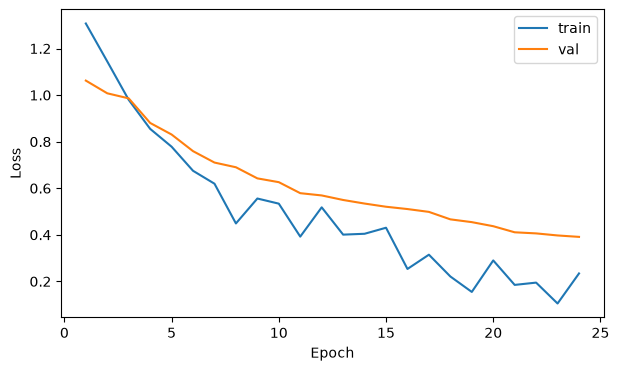

VALIDATION
              precision    recall  f1-score   support

      garden       0.83      1.00      0.91         5
  not_garden       1.00      0.80      0.89         5
    unusable       1.00      1.00      1.00         5

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15

[[5 0 0]
 [1 4 0]
 [0 0 5]]


In [6]:
display(pd.DataFrame(history))
fig,ax=plt.subplots(figsize=(7,4));ax.plot([h['epoch'] for h in history],[h['train_loss'] for h in history],label='train');ax.plot([h['epoch'] for h in history],[h['val_loss'] for h in history],label='val');ax.legend();ax.set_xlabel('Epoch');ax.set_ylabel('Loss');plt.show()
def predictions(split):
 ys=[];preds=[]
 with torch.inference_mode():
  for x,y in loaders[split]:
   out=model(x.to(DEVICE));ys.extend(y.tolist());preds.extend(out.argmax(1).cpu().tolist())
 return ys,preds
val_y,val_pred=predictions('val')
print('VALIDATION');print(classification_report(val_y,val_pred,labels=list(range(3)),target_names=CLASSES,zero_division=0))
print(confusion_matrix(val_y,val_pred,labels=list(range(3))))


## Test final et export

Ne lancer le test qu'une fois le modèle choisi. Ne pas ajuster les hyperparamètres à partir du résultat du test. Les métadonnées conservent l'ordre exact des classes requis par FastAPI.

In [7]:
test_y,test_pred=predictions('test')
print('TEST');print(classification_report(test_y,test_pred,labels=list(range(3)),target_names=CLASSES,zero_division=0))
print(confusion_matrix(test_y,test_pred,labels=list(range(3))))
weights_dir=ROOT/'models/weights';metadata_dir=ROOT/'models/metadata'
weights_dir.mkdir(parents=True,exist_ok=True);metadata_dir.mkdir(parents=True,exist_ok=True)
weight_path=weights_dir/'garden_resnet18_v2.pth';meta_path=metadata_dir/'garden_resnet18_v2.json'
# Save plain state_dict compatible with validation/app/models/resnet18_model.py
torch.save({k:v.detach().cpu() for k,v in best_state.items()},weight_path)
meta={'architecture':'resnet18','version':'v2','classes':CLASSES,'pretrained_weights':'ResNet18_Weights.IMAGENET1K_V1','seed':SEED,'mean':MEAN,'std':STD,'split_file':'datasets/splits/garden_split_v2.csv','split_strategy':'group_based','training_images':int((df.split=='train').sum()),'validation_images':int((df.split=='val').sum()),'test_images':int((df.split=='test').sum()),'validation_accuracy':float(accuracy_score(val_y,val_pred)),'test_accuracy':float(accuracy_score(test_y,test_pred)),'macro_f1':float(f1_score(test_y,test_pred,average='macro',zero_division=0)),'note':'Human-reviewed small dataset; metrics exploratory. Blur derivatives restricted to train.'}
meta_path.write_text(json.dumps(meta,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
print('Weights:',weight_path,'\nMetadata:',meta_path)


TEST
              precision    recall  f1-score   support

      garden       1.00      1.00      1.00         4
  not_garden       1.00      1.00      1.00         5
    unusable       1.00      1.00      1.00         5

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14

[[4 0 0]
 [0 5 0]
 [0 0 5]]
Weights: /home/bsui/projects/GardnAIze/models/weights/garden_resnet18_v2.pth 
Metadata: /home/bsui/projects/GardnAIze/models/metadata/garden_resnet18_v2.json


## Contrôle de compatibilité FastAPI

La V1 n'est pas remplacée. Pour activer V2, configurer le conteneur avec `VALID_MODEL_PATH=/models/weights/garden_resnet18_v2.pth` et `VALID_METADATA_PATH=/models/metadata/garden_resnet18_v2.json`, en montant les deux répertoires dans le conteneur. Vérifier le comportement de `/api/v1/model/info`, `/api/v1/health` et l'inférence avec une vraie photo.

**Git :** commiter les notebooks, métadonnées et manifestes autorisés. Ne pas commiter `.pth`, checkpoints ni photos sans droits de redistribution.